# Logistic Regression: Diabetes Prediction
Binary classification: predict `Outcome` (1 = diabetic, 0 = not diabetic) from 7 clinical features.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\Users\Dell\Documents\Intro to AI - LABWorks\LAB 4\diabetes.csv")  # put the CSV next to the notebook, or use a full path
print(df.shape)
df.head()

(768, 8)


,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,148,72.0,35,169.5,33.6,0.627,50,1
1,85,66.0,29,102.5,26.6,0.351,31,0
2,183,64.0,32,169.5,23.3,0.672,32,1
3,89,66.0,23,94.0,28.1,0.167,21,0
4,137,40.0,35,168.0,43.1,2.288,33,1


## 1. Explore the data

In [5]:
print(df.isna().sum())
print()
print(df["Outcome"].value_counts())
df.describe().T

Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Outcome
0    500
1    268
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
Glucose,768.0,121.677083,30.464161,44.000,99.75000,117.0000,140.25000,199.00
BloodPressure,768.0,72.389323,12.106039,24.000,64.00000,72.0000,80.00000,122.00
SkinThickness,768.0,29.089844,8.890820,7.000,25.00000,28.0000,32.00000,99.00
Insulin,768.0,141.753906,89.100847,14.000,102.50000,102.5000,169.50000,846.00
BMI,768.0,32.434635,6.880498,18.200,27.50000,32.0500,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


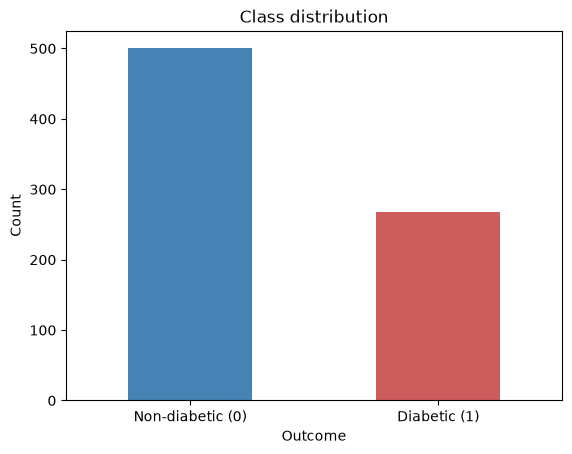

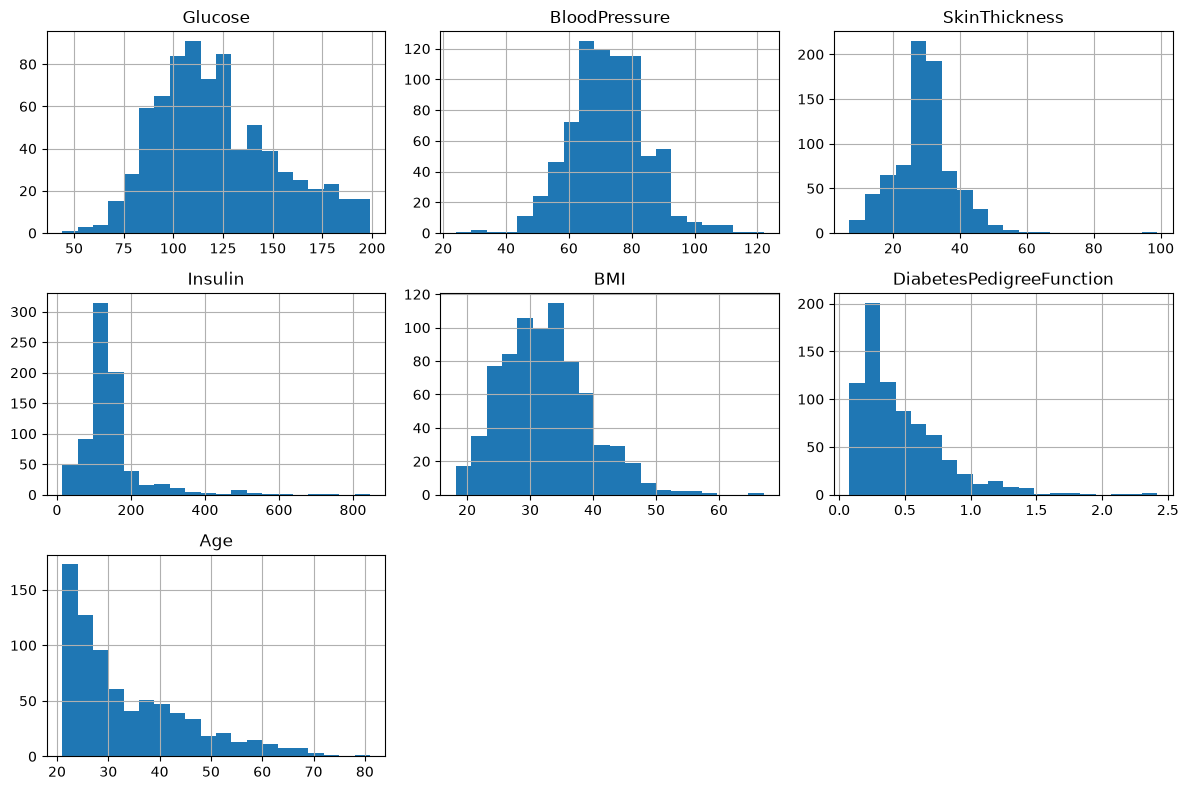

In [6]:
df["Outcome"].value_counts().plot(kind="bar", color=["steelblue", "indianred"])
plt.xticks([0, 1], ["Non-diabetic (0)", "Diabetic (1)"], rotation=0)
plt.ylabel("Count")
plt.title("Class distribution")
plt.show()

df.drop(columns="Outcome").hist(figsize=(12, 8), bins=20)
plt.tight_layout()
plt.show()

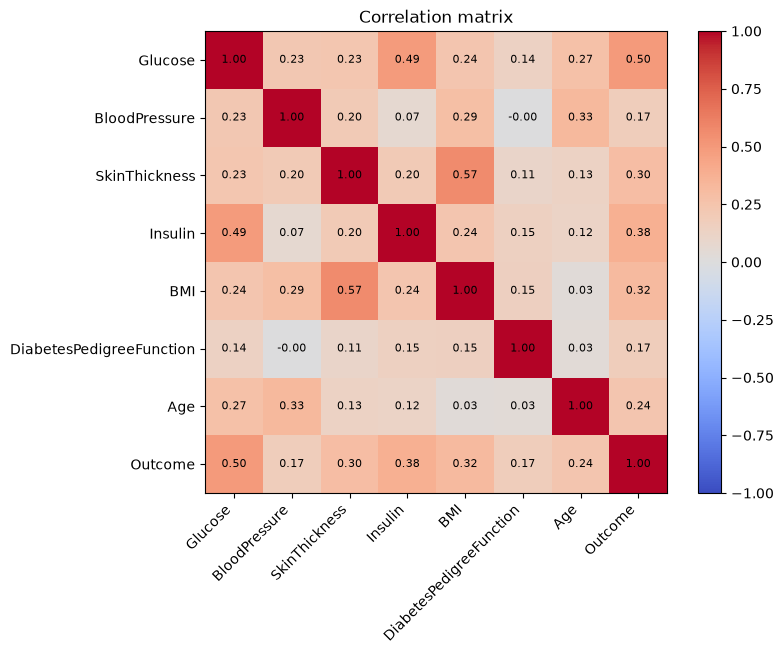

In [7]:
corr = df.corr()
plt.figure(figsize=(8, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.title("Correlation matrix")
plt.show()

## 2. Train/test split
Stratified so both sets keep the ~35% diabetic ratio.

In [8]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="Outcome")
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

(614, 7) (154, 7)


## 3. Scale features and train
The features are on very different scales (Insulin up to 846, DiabetesPedigreeFunction under 3), so we standardize them. The scaler is fit on the training set only, to avoid leaking test information. A `Pipeline` keeps both steps together.

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000)),
])
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['Glucose','BloodPressure','SkinThickness',...,'BMI', 'DiabetesPedigreeFunction','Age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


## 4. Predictions

In [10]:
y_predict = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

results = X_test.copy()
results["Actual"] = y_test.values
results["Predicted"] = y_predict
results["P(Diabetic)"] = y_proba.round(3)
results.head(10)

,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Actual,Predicted,P(Diabetic)
44,159,64.0,27,102.5,27.4,0.294,40,0,0,0.418
672,68,106.0,23,49.0,35.5,0.285,47,0,0,0.052
700,122,76.0,27,200.0,35.9,0.483,26,0,0,0.396
630,114,64.0,32,169.5,27.4,0.732,34,1,0,0.274
81,74,70.0,27,102.5,30.1,0.102,22,0,0,0.035
389,100,68.0,23,81.0,31.6,0.949,28,0,0,0.103
387,105,100.0,36,169.5,43.3,0.239,45,1,1,0.506
408,197,74.0,32,169.5,25.9,1.191,39,1,1,0.861
163,100,64.0,23,102.5,29.7,0.368,21,0,0,0.070
335,165,76.0,43,255.0,47.9,0.259,26,0,1,0.926


## 5. Evaluation

In [11]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)

print(f"Accuracy : {accuracy_score(y_test, y_predict):.3f}")
print(f"Precision: {precision_score(y_test, y_predict):.3f}")
print(f"Recall   : {recall_score(y_test, y_predict):.3f}")
print(f"F1       : {f1_score(y_test, y_predict):.3f}")
print(f"ROC AUC  : {roc_auc_score(y_test, y_proba):.3f}")
print()
print(classification_report(y_test, y_predict, target_names=["Non-diabetic", "Diabetic"]))

Accuracy : 0.727
Precision: 0.625
Recall   : 0.556
F1       : 0.588
ROC AUC  : 0.817

              precision    recall  f1-score   support

Non-diabetic       0.77      0.82      0.80       100
    Diabetic       0.62      0.56      0.59        54

    accuracy                           0.73       154
   macro avg       0.70      0.69      0.69       154
weighted avg       0.72      0.73      0.72       154



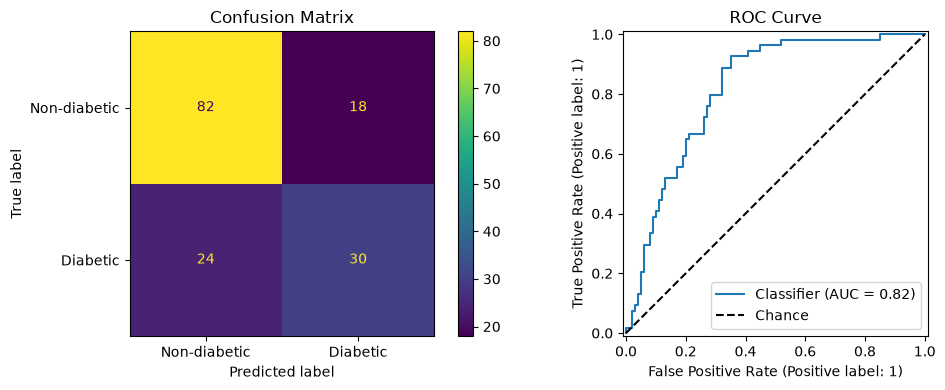

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_predict, display_labels=["Non-diabetic", "Diabetic"], ax=ax[0]
)
ax[0].set_title("Confusion Matrix")
RocCurveDisplay.from_predictions(y_test, y_proba, ax=ax[1])
ax[1].plot([0, 1], [0, 1], "k--", label="Chance")
ax[1].set_title("ROC Curve")
ax[1].legend()
plt.tight_layout()
plt.show()

## 6. Which features matter?
Because the features are standardized, the coefficients are directly comparable. `exp(coef)` is the odds ratio for a 1-standard-deviation increase in that feature.

                    Feature  Coefficient  Odds ratio
0                   Glucose     0.917692    2.503505
1                   Insulin     0.630830    1.879170
2                       BMI     0.441927    1.555702
3                       Age     0.310199    1.363696
4             SkinThickness     0.301106    1.351353
5  DiabetesPedigreeFunction     0.153351    1.165734
6             BloodPressure     0.018612    1.018786


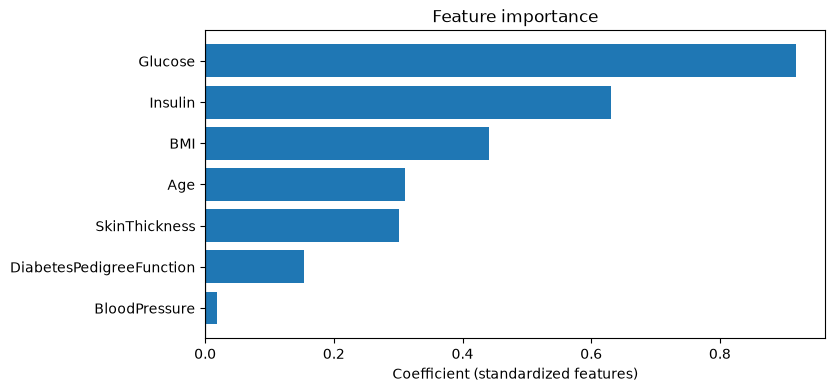

In [13]:
coefs = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.named_steps["clf"].coef_[0],
})
coefs["Odds ratio"] = np.exp(coefs["Coefficient"])
coefs = coefs.sort_values("Coefficient", ascending=False).reset_index(drop=True)
print(coefs)

plt.figure(figsize=(8, 4))
plt.barh(coefs["Feature"][::-1], coefs["Coefficient"][::-1])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coefficient (standardized features)")
plt.title("Feature importance")
plt.show()

## 7. Cross-validation
With only 768 rows, a single split can be misleading, so check stability across 5 folds.

In [14]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for metric in ["accuracy", "recall", "roc_auc"]:
    scores = cross_val_score(model, X, y, cv=cv, scoring=metric)
    print(f"{metric:9s}: {scores.mean():.3f} ± {scores.std():.3f}")

accuracy : 0.771 ± 0.040
recall   : 0.582 ± 0.022
roc_auc  : 0.853 ± 0.027


## 8. Predict for a new patient

In [15]:
new_patient = pd.DataFrame([{
    "Glucose": 150, "BloodPressure": 80, "SkinThickness": 30,
    "Insulin": 150, "BMI": 35.0, "DiabetesPedigreeFunction": 0.6, "Age": 45,
}])
p = model.predict_proba(new_patient)[0, 1]
print(f"P(diabetic) = {p:.1%} -> predicted class: {int(p >= 0.5)}")

P(diabetic) = 65.7% -> predicted class: 1


> **Note:** this is a learning exercise, not a diagnostic tool.